<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/RNN_P5_implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Implementing an RNN from Scratch

Now that we understand how an RNN works conceptually, we will implement one using TensorFlow.

We will train a **character-level language model** using *The Time Machine* dataset.

The task is **next-character prediction**:

Input:  `m a c h i n`  
Target: `a c h i n e`

At each time step, the RNN:

1. receives the current character,
2. combines it with the previous hidden state,
3. calculates a new hidden state,
4. produces an output for predicting the next character.

The main RNN computation is:

$$
H_t = \phi(X_tW_{xh} + H_{t-1}W_{hh} + b_h)
$$

followed by:

$$
O_t = H_tW_{hq} + b_q
$$

We will now implement these computations directly in TensorFlow.

In [1]:
!pip install --q D2l --no-deps

In [2]:
import math
import tensorflow as tf
from d2l import tensorflow as d2l

### Building the RNN Model

We now implement the RNN computation directly in TensorFlow.

Recall that the hidden state is calculated as:

$$
H_t = \tanh(X_tW_{xh} + H_{t-1}W_{hh} + b_h)
$$

The model therefore needs three trainable parameters:

- $W_{xh}$ — weights from the **input to the hidden state**
- $W_{hh}$ — weights from the **previous hidden state to the new hidden state**
- $b_h$ — hidden-state bias

These parameters are shared across all time steps.

In [3]:
class RNNScratch(d2l.Module):
    """RNN implemented from scratch."""

    def __init__(self, num_inputs, num_hiddens, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()

        # Weights connecting the current input to the hidden state
        self.W_xh = tf.Variable(
            tf.random.normal((num_inputs, num_hiddens)) * sigma
        )

        # Recurrent weights connecting the previous hidden state
        # to the new hidden state
        self.W_hh = tf.Variable(
            tf.random.normal((num_hiddens, num_hiddens)) * sigma
        )

        # Bias for the hidden state
        self.b_h = tf.Variable(tf.zeros(num_hiddens))

### Forward Pass Through Time

The RNN processes the sequence **one time step at a time**.

At each time step, it takes:

1. the current input $X_t$
2. the previous hidden state $H_{t-1}$

and calculates the new hidden state:

$$
H_t = \tanh(X_tW_{xh} + H_{t-1}W_{hh} + b_h)
$$

The new hidden state is then passed to the next time step.

If there is no previous hidden state, we initialize it with zeros.

In [4]:
@d2l.add_to_class(RNNScratch)
def forward(self, inputs, state=None):

    # If this is the beginning of the sequence,
    # initialize the hidden state with zeros.
    if state is None:
        state = tf.zeros((inputs.shape[1], self.num_hiddens))
    else:
        state = tf.reshape(state, (-1, self.num_hiddens))

    outputs = []

    # Process one time step at a time
    for X in inputs:

        # RNN equation:
        # current input + previous hidden state -> new hidden state
        state = tf.tanh(
            tf.matmul(X, self.W_xh) +
            tf.matmul(state, self.W_hh) +
            self.b_h
        )

        # Save the hidden state for this time step
        outputs.append(state)

    return outputs, state

for X in inputs:

Take one time step, update the memory, move to the next time step.
X1 + H0 → H1

X2 + H1 → H2

X3 + H2 → H3

X4 + H3 → H4
...

Here we test the RNN with:

- **100 time steps**
- **2 sequences in each batch**
- **16 input features**
- **32 hidden units**

The RNN produces one hidden-state output for each time step, while `state`
contains the final hidden state after processing the sequence.

In [5]:
# Define the test dimensions.
batch_size = 2
num_inputs = 16
num_hiddens = 32
num_steps = 100

# Create the RNN.
rnn = RNNScratch(num_inputs, num_hiddens)

# Create a dummy input:
# 100 time steps, 2 examples per batch, 16 input features.
X = tf.ones((num_steps, batch_size, num_inputs))

# Run the sequence through the RNN.
outputs, state = rnn(X)

# Display the important dimensions.
print("Number of time-step outputs:", len(outputs))
print("Shape of one output:", outputs[0].shape)
print("Final hidden-state shape:", state.shape)

Number of time-step outputs: 100
Shape of one output: (2, 32)
Final hidden-state shape: (2, 32)



Before testing the RNN, we specify four important dimensions:

- **`batch_size`** = number of sequences processed in parallel.
- **`num_steps`** = number of time steps (tokens) in each sequence.
- **`num_inputs`** = number of features used to represent one token at each time step.
- **`num_hiddens`** = number of hidden units used to represent the RNN's memory at each time step.


## RNN-Based Language Model

So far, our RNN produces a **hidden state** at each time step.

Now we need to turn that hidden state into a prediction of the **next token**.

The output layer computes:

$$
O_t = H_tW_{hq} + b_q
$$

where:

- $H_t$ = hidden state containing information from the sequence so far
- $W_{hq}$ = weights connecting the hidden state to the output
- $b_q$ = output bias
- $O_t$ = scores for all possible tokens in the vocabulary

The output has one score for **every token in the vocabulary**.

For example, after reading:

`the tim`

the model might produce probabilities such as:

- `e` → 0.75
- `a` → 0.08
- `s` → 0.03
- other characters → lower probabilities

The correct next character is `e`.

During training, **cross-entropy loss** compares these predicted probabilities with the actual next token.

The model is evaluated using **perplexity**:

$$
\text{Perplexity} = e^{\text{cross-entropy loss}}
$$

> **Lower perplexity means the model is better at predicting the next token.**

In [8]:
class RNNLMScratch(d2l.Classifier):
    """RNN-based language model implemented from scratch."""

    def __init__(self, rnn, vocab_size, lr=0.01):
        super().__init__()
        self.save_hyperparameters()

        # Create the output-layer parameters
        self.init_params()

    def init_params(self):
        # W_hq connects the hidden state to the output layer.
        # It converts the RNN's memory into scores for every token
        # in the vocabulary.
        #
        # Shape:
        # (num_hiddens, vocab_size)
        self.W_hq = tf.Variable(
            tf.random.normal(
                (self.rnn.num_hiddens, self.vocab_size)
            ) * self.rnn.sigma
        )

        # One bias value for each possible token in the vocabulary
        self.b_q = tf.Variable(tf.zeros(self.vocab_size))



    def validation_step(self, batch):
        # Evaluate the model on validation data
        l = self.loss(self(*batch[:-1]), batch[-1])

        # Report validation perplexity
        self.plot('ppl', tf.exp(l), train=False)

key: self.W_hq

current token

     ↓

   W_xh

     ↓

hidden state ← W_hh ← previous hidden state

     ↓

   W_hq

     ↓
     
next-token prediction

## One-Hot Encoding

After tokenization, each token has a numerical index. However, we should not feed the index directly into the RNN.

For example, suppose our vocabulary is:

| Token | Index |
| ----- | ----: |
| a     |     0 |
| b     |     1 |
| c     |     2 |
| d     |     3 |
| e     |     4 |

Using these numbers directly would incorrectly suggest that token `2` is somehow numerically closer to token `3` than to token `0`.

Instead, we use **one-hot encoding**.

A one-hot vector has:

- one position for every token in the vocabulary
- a **1** at the position of the current token
- **0** everywhere else

For example, if the vocabulary size is 5:

$$
0 \rightarrow [1, 0, 0, 0, 0]
$$

$$
2 \rightarrow [0, 0, 1, 0, 0]
$$

Therefore, token `c`, whose index is `2`, becomes:

`[0, 0, 1, 0, 0]`

> **The length of the one-hot vector equals the vocabulary size.**


### How Does the RNN Use This Vector?

Recall the RNN hidden-state equation:

$$
H_t = \tanh(X_t W_{xh} + H_{t-1}W_{hh} + b_h)
$$

At time step $t$:

- $X_t$ = one-hot representation of the current token
- $H_{t-1}$ = memory from the previous time step
- $W_{xh}$ = weights from the input to the hidden state
- $W_{hh}$ = weights from the previous hidden state to the new hidden state
- $H_t$ = updated hidden state

For example, suppose the current character is `c`.

Its index is:

`2`

After one-hot encoding:

`X_t = [0, 0, 1, 0, 0]`

The RNN then uses this vector in:

$$
X_t W_{xh}
$$

Because only the third position of $X_t$ is 1, this multiplication selects the part of $W_{xh}$ associated with character `c`.

That information is then combined with the previous hidden state:

$$
H_{t-1}W_{hh}
$$

to produce the new hidden state $H_t$.

Conceptually:

`current token → one-hot vector → combine with previous memory → new hidden state`

For example:

`c → [0,0,1,0,0] → RNN → updated memory`



### What Happens with a Batch?

We usually process several sequences in parallel.

Before one-hot encoding, the input has shape:

`(batch_size, num_steps)`

For example:

`batch_size = 2`

means **2 sequences are processed in parallel**.

After one-hot encoding and transposing, the input has shape:

`(num_steps, batch_size, vocab_size)`

At each time step, the RNN receives one one-hot vector from each sequence in the batch.

For a character-level RNN using one-hot encoding:

`num_inputs = vocab_size`

So if the vocabulary contains **28 unique characters**, each character is represented by a **28-dimensional one-hot vector**.

In [9]:
# One-hot encode token indices 0 and 2
# Vocabulary size = 5
tf.one_hot(tf.constant([0, 2]), 5)

<tf.Tensor: shape=(2, 5), dtype=float32, numpy=
array([[1., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0.]], dtype=float32)>

In [11]:
@d2l.add_to_class(RNNLMScratch)
def one_hot(self, X):
    # X originally has shape:
    # (batch_size, num_steps)

    # Transpose so we can process the sequence time step by time step,
    # then convert every token index into a one-hot vector.
    #
    # Final shape:
    # (num_steps, batch_size, vocab_size)
    return tf.one_hot(tf.transpose(X), self.vocab_size)

## Transforming RNN Outputs into Token Predictions

The RNN produces a hidden state at each time step, but the hidden state is **not yet a prediction**.

The hidden state is passed through a fully connected output layer:

$$
O_t = H_t W_{hq} + b_q
$$

where:

- $H_t$ = hidden state at time step $t$
- $W_{hq}$ = weights connecting the hidden state to the output
- $b_q$ = output bias
- $O_t$ = scores for all possible next tokens

For example, after reading:

`m → a → c`

the hidden state contains information about `mac`.

The output layer converts that hidden state into scores for all possible next characters.

A **softmax** then converts these scores into probabilities:

`a: 0.02, b: 0.01, ..., h: 0.72, ...`

So the model gives a high probability to `h` as the next character.

> **RNN hidden state → output layer → softmax → next-token probabilities**

In [12]:
@d2l.add_to_class(RNNLMScratch)
def output_layer(self, rnn_outputs):

    # Convert each hidden state H_t into scores
    # for every possible next token
    outputs = [
        tf.matmul(H, self.W_hq) + self.b_q
        for H in rnn_outputs
    ]

    # Combine predictions from all time steps
    return tf.stack(outputs, 1)


@d2l.add_to_class(RNNLMScratch)
def forward(self, X, state=None):

    # Convert token indices to one-hot vectors
    embs = self.one_hot(X)

    # Process the sequence through the RNN
    # and obtain a hidden state at each time step
    rnn_outputs, _ = self.rnn(embs, state)

    # Convert hidden states into next-token scores
    return self.output_layer(rnn_outputs)

## Gradient Clipping

RNNs are trained using **backpropagation through time (BPTT)**.

During backpropagation, the model calculates a gradient for each trainable parameter. These gradients tell us how the loss changes with respect to the model parameters.

For simplicity, suppose backpropagation gives us two gradient values:

$$
g = [12,16]
$$

> This two-value gradient is only a simple example. A real RNN has many parameters and therefore many gradient values.



### Measuring the Size of the Gradient

To determine whether the gradients are becoming too large, we calculate their overall size, called the **gradient norm**.

For a gradient vector

$$
g=[g_1,g_2,\ldots,g_n]
$$

the norm is:

$$
\|g\|=\sqrt{g_1^2+g_2^2+\cdots+g_n^2}
$$

For our example:

$$
g=[12,16]
$$

so:

$$
\|g\|=\sqrt{12^2+16^2}
$$

$$
=\sqrt{144+256}=20
$$

Therefore, the **size of the gradient is 20**.

### Why Is a Large Gradient a Problem?

The model parameters are updated approximately as:

$$
W_{\text{new}} = W_{\text{old}} - \eta g
$$

where:

- $\eta$ = learning rate
- $g$ = gradient

If the gradient becomes extremely large, the weight update can also become extremely large. This can make RNN training unstable. This problem is called an **exploding gradient**.


### Gradient Clipping

To prevent this, we choose a maximum allowed gradient norm called the **clipping threshold**.

Let:

$$
\theta = 5
$$

The threshold $\theta$ is a **hyperparameter chosen by us**. It is not calculated by backpropagation.

Gradient clipping uses:

$$
g \leftarrow \min\left(1,\frac{\theta}{\|g\|}\right)g
$$

where:

- $g$ = gradient calculated by backpropagation
- $\|g\|$ = size of the gradient calculated using the norm formula
- $\theta$ = maximum allowed gradient norm chosen by us


### Example

We calculated:

$$
\|g\|=20
$$

and suppose we choose:

$$
\theta=5
$$

Since:

$$
20 > 5
$$

the gradient is too large.

We calculate the scaling factor:

$$
\frac{\theta}{\|g\|}
=
\frac{5}{20}
=
0.25
$$

Then scale every gradient value:

$$
g_{\text{new}}
=
0.25[12,16]
$$

$$
g_{\text{new}}=[3,4]
$$

Now check its size:

$$
\|g_{\text{new}}\|
=
\sqrt{3^2+4^2}
=
5
$$

So gradient clipping changed the gradient norm from **20 to 5** while keeping the same direction.

> **Key idea:** Backpropagation produces the gradient values. We calculate their overall size using the gradient norm. If that size exceeds a threshold chosen by us, gradient clipping scales the gradients down to that threshold.

> **Key idea:** Gradient clipping limits excessively large gradients during
> training. If the gradient norm exceeds a chosen threshold, the gradient
> is scaled down while preserving its direction. This helps stabilize RNN
> training and prevents exploding gradients.

In [13]:
@d2l.add_to_class(d2l.Trainer)
def clip_gradients(self, grad_clip_val, grads):
    """Clip gradients so their overall norm does not exceed grad_clip_val."""

    # Convert the clipping threshold to a TensorFlow constant.
    grad_clip_val = tf.constant(grad_clip_val, dtype=tf.float32)

    # Convert sparse gradients to regular tensors when needed.
    new_grads = [
        tf.convert_to_tensor(grad)
        if isinstance(grad, tf.IndexedSlices)
        else grad
        for grad in grads
    ]

    # Compute the overall gradient norm:
    # sqrt(g1^2 + g2^2 + ... + gn^2)
    norm = tf.math.sqrt(
        sum(tf.reduce_sum(grad ** 2) for grad in new_grads)
    )

    # If the gradient norm is larger than the threshold,
    # scale all gradients down by:
    #
    # threshold / current norm
    if tf.greater(norm, grad_clip_val):

        for i, grad in enumerate(new_grads):
            new_grads[i] = grad * grad_clip_val / norm

        return new_grads

    # If the gradient norm is already below the threshold,
    # leave the gradients unchanged.
    return grads

## Training the RNN Language Model

Now we combine the pieces developed earlier and train the character-level RNN on *The Time Machine*.

The important settings are:

- `batch_size = 1024`: process 1024 sequences in parallel.
- `num_steps = 32`: each training sequence contains 32 time steps (characters).
- `num_hiddens = 32`: the hidden state contains 32 values.
- `lr = 1`: learning rate used to update the parameters.
- `max_epochs = 100`: the model passes through the training process for 100 epochs.
- `gradient_clip_val = 1`: if the overall gradient norm exceeds 1, it is scaled down.

During training, the model repeatedly:

1. receives the input character sequences,
2. updates the hidden state through the RNN,
3. predicts the next character at each time step,
4. compares the predictions with the target characters,
5. computes the loss and gradients,
6. clips excessively large gradients,
7. updates the model parameters.

The training progress is measured using **perplexity (PPL)**. Lower perplexity means the model is becoming better at predicting the next character.

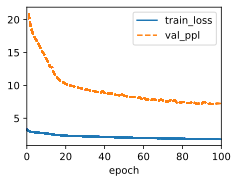

In [15]:
# Load the Time Machine dataset
data = d2l.TimeMachine(batch_size=1024, num_steps=32)

with d2l.try_gpu():

    # Create the RNN
    rnn = RNNScratch(
        num_inputs=len(data.vocab),
        num_hiddens=32
    )

    # Create the RNN language model
    model = RNNLMScratch(
        rnn,
        vocab_size=len(data.vocab),
        lr=1.0
    )

# --------------------------------------------------
# Compatibility fixes for current Keras
# --------------------------------------------------

# Make sure Keras tracks the variables created manually
model._track_variable(rnn.W_xh)
model._track_variable(rnn.W_hh)
model._track_variable(rnn.b_h)
model._track_variable(model.W_hq)
model._track_variable(model.b_q)

# Define cross-entropy loss
cross_entropy = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

# D2L calls loss(prediction, target),
# while Keras expects loss(target, prediction)
model.loss = lambda prediction, target: cross_entropy(
    target, prediction
)

# --------------------------------------------------
# Train
# --------------------------------------------------

trainer = d2l.Trainer(
    max_epochs=100,
    gradient_clip_val=1.0
)

trainer.fit(model, data)

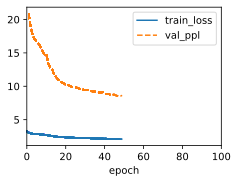

In [ ]:
# ============================================================
# 1. Prepare the training data
# ============================================================

# Load character sequences from The Time Machine.
#
# batch_size = 1024:
#   Train on 1024 sequences at the same time.
#
# num_steps = 32:
#   Each sequence contains 32 consecutive characters/time steps.
data = d2l.TimeMachine(
    batch_size=1024,
    num_steps=32
)


# ============================================================
# 2. Build the RNN
# ============================================================

with d2l.try_gpu():

    # Each character is represented by a one-hot vector.
    # Therefore:
    #
    #   num_inputs = vocabulary size
    #
    # If there are 28 unique characters, each input character
    # is represented by a vector of length 28.
    #
    # num_hiddens = 32 means the hidden state H_t
    # contains 32 values that carry information from previous
    # time steps.
    rnn = RNNScratch(
        num_inputs=len(data.vocab),
        num_hiddens=32
    )

    # Add the language-model output layer to the RNN.
    #
    # At every time step:
    #
    #   current character
    #          ↓
    #        RNN
    #          ↓
    #   hidden state H_t
    #          ↓
    #   output scores for every possible next character
    #
    # vocab_size tells the model how many possible
    # characters it can predict.
    model = RNNLMScratch(
        rnn,
        vocab_size=len(data.vocab),
        lr=1.0
    )


# ============================================================
# 3. Tell current Keras which variables must be learned
# ============================================================

# RNNScratch creates its weights manually with tf.Variable.
# Current Keras does not automatically recognize all of these
# variables as trainable weights, so we explicitly register them.
#
# W_xh : input  -> hidden weights
# W_hh : previous hidden state -> current hidden state
# b_h  : hidden-state bias
# W_hq : hidden -> output weights
# b_q  : output bias
#
# These are the parameters that training will update.
model._track_variable(rnn.W_xh)
model._track_variable(rnn.W_hh)
model._track_variable(rnn.b_h)
model._track_variable(model.W_hq)
model._track_variable(model.b_q)


# ============================================================
# 4. Define how prediction error is measured
# ============================================================

# At each time step, the model must predict the next character.
#
# Example:
#
#   input:   m
#   target:  a
#
# The model produces a score for every character in the
# vocabulary. Cross-entropy measures how far those predictions
# are from the correct next character.
#
# from_logits=True because the model outputs raw scores (logits),
# not probabilities.
cross_entropy = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

# D2L calls the loss as:
#
#   loss(prediction, target)
#
# while Keras expects:
#
#   loss(target, prediction)
#
# This small wrapper puts them in the order Keras expects.
model.loss = lambda prediction, target: cross_entropy(
    target,
    prediction
)


# ============================================================
# 5. Set up training
# ============================================================

# Train the model for 100 complete passes through the data.
#
# gradient_clip_val = 1.0:
# If the overall gradient becomes too large, scale it down
# so that its norm does not exceed 1.
#
# This helps prevent exploding gradients in the RNN.
trainer = d2l.Trainer(
    max_epochs=100,
    gradient_clip_val=1.0
)


# ============================================================
# 6. Train the model
# ============================================================

# During training, the model repeatedly:
#
#   characters
#       ↓
#   one-hot encoding
#       ↓
#   RNN hidden states
#       ↓
#   next-character predictions
#       ↓
#   cross-entropy loss
#       ↓
#   gradients
#       ↓
#   gradient clipping
#       ↓
#   update W_xh, W_hh, W_hq and the biases
#
trainer.fit(model, data)

In [ ]:
# ============================================================
# Show actual next-character predictions
# ============================================================

# Look at the first sequence in the batch.
input_ids = X[0].numpy()
target_ids = Y[0].numpy()
predicted_ids = predictions[0].numpy()

# Convert numerical character IDs back into characters.
input_text = ''.join(data.vocab.to_tokens(input_ids))
target_text = ''.join(data.vocab.to_tokens(target_ids))
predicted_text = ''.join(data.vocab.to_tokens(predicted_ids))

print("Input:     ", input_text)
print("Target:    ", target_text)
print("Predicted: ", predicted_text)

In [ ]:
# ============================================================
# Examine individual next-character predictions
# ============================================================

# Look at the first sequence in the batch.
input_ids = X[0].numpy()
target_ids = Y[0].numpy()
predicted_ids = predictions[0].numpy()

print("Current | Correct Next | Predicted | Correct?")
print("----------------------------------------------")

# Show the first 15 time steps.
for i in range(15):

    current_char = data.vocab.idx_to_token[input_ids[i]]
    target_char = data.vocab.idx_to_token[target_ids[i]]
    predicted_char = data.vocab.idx_to_token[predicted_ids[i]]

    correct = "YES" if target_char == predicted_char else "NO"

    # repr() makes spaces visible as ' '
    print(
        f"{repr(current_char):7} | "
        f"{repr(target_char):12} | "
        f"{repr(predicted_char):9} | "
        f"{correct}"
    )